# Handwritten Digit Recognition Using Neural Networks (MNIST)

**Internship project | Artificial Intelligence**


## 1. Import libraries
We use TensorFlow/Keras to build the neural network, NumPy for array operations, and Matplotlib to display images and graphs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load the MNIST dataset
Keras provides the MNIST dataset. It is split into training and test sets.

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


## 3. View a few images
The images are 28 by 28 pixels. Labels indicate the digit shown in each image.

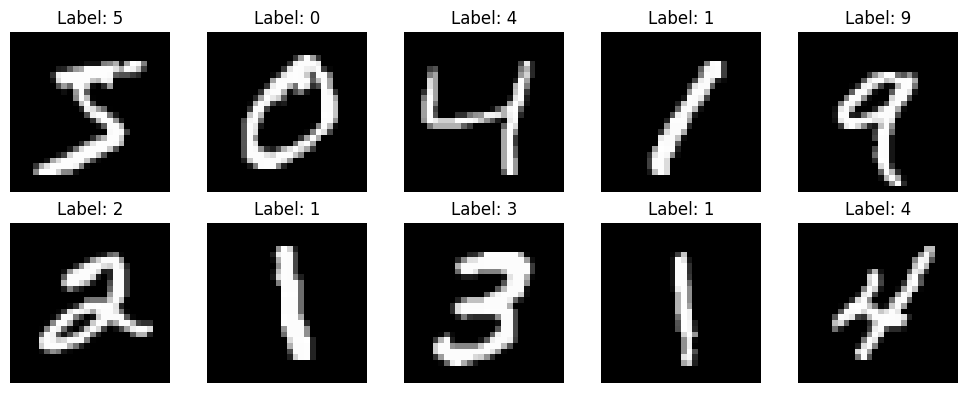

In [4]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Preprocess the images
Pixel values are originally between 0 and 255. Dividing by 255 converts them to values between 0 and 1. This helps training.

In [ ]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print("Training pixel range:", x_train.min(), "to", x_train.max())

## 5. Build the neural network
Flatten converts each 28×28 image into a vector. Dense layers learn patterns. The final 10-unit layer produces scores for digits 0 through 9.

In [5]:
model = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile the model
Adam is the optimizer. Sparse categorical cross-entropy is used because the labels are integer digits. Accuracy is monitored during training.

In [6]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## 7. Train the model
Training runs for up to 10 epochs. A validation split allows us to monitor performance on data not used to update the model weights.

In [7]:
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.7482 - loss: 2.5664 - val_accuracy: 0.9027 - val_loss: 0.4412
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8400 - loss: 0.6007 - val_accuracy: 0.9247 - val_loss: 0.3130
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8690 - loss: 0.4923 - val_accuracy: 0.9268 - val_loss: 0.3084
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8812 - loss: 0.4464 - val_accuracy: 0.9397 - val_loss: 0.2598
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8922 - loss: 0.4107 - val_accuracy: 0.9405 - val_loss: 0.2411
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8973 - loss: 0.3978 - val_accuracy: 0.9467 - val_loss: 0.2357
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9035 - loss: 0.3739 - val_accuracy: 0.9502 - val_loss: 0.2054
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9084 - loss: 0.3585 -

## 8. Plot accuracy and loss
These graphs show how training and validation performance changed across epochs. Save screenshots for the report.

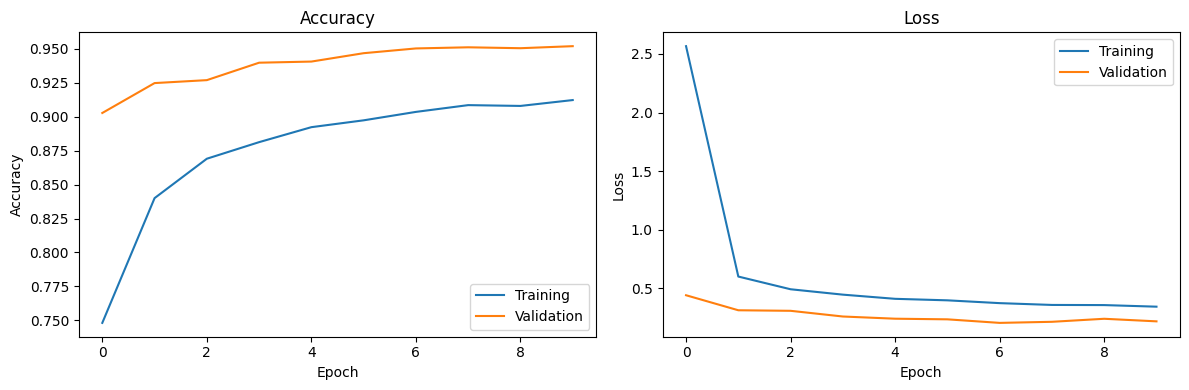

In [8]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Evaluate on test data
The test set is held out from training. The score below is the model's performance on that set.

In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")

Test loss: 0.2951
Test accuracy: 0.9377 (93.77%)


## 10. Classification report and confusion matrix
The report includes precision, recall and F1-score for each digit. The confusion matrix shows which digits the model confused.

              precision    recall  f1-score   support

           0       0.98      0.96      0.97       980
           1       0.99      0.98      0.98      1135
           2       0.96      0.93      0.94      1032
           3       0.94      0.92      0.93      1010
           4       0.96      0.92      0.94       982
           5       0.95      0.90      0.92       892
           6       0.95      0.97      0.96       958
           7       0.97      0.93      0.95      1028
           8       0.78      0.95      0.86       974
           9       0.93      0.92      0.92      1009

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.94      0.94      0.94     10000



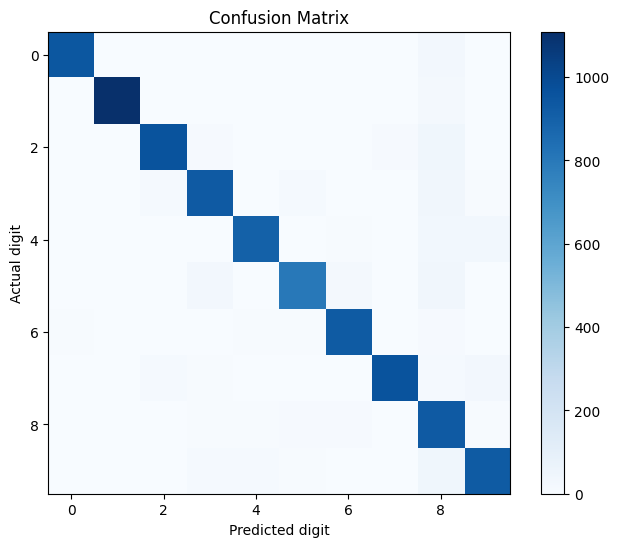

In [10]:
y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted digit")
plt.ylabel("Actual digit")
plt.colorbar()
plt.show()

## 11. Display sample predictions
This cell displays several test images alongside the model's predictions.

In [ ]:
plt.figure(figsize=(12, 5))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"Actual: {y_test[i]} | Predicted: {y_pred[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 12. Predict a selected test image
Change the index to view another example.

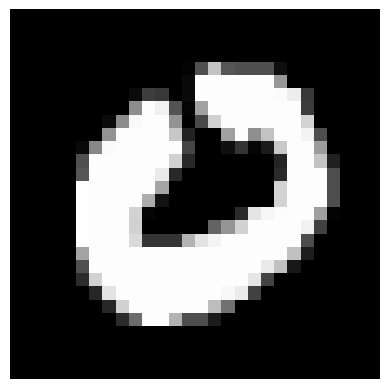

Predicted digit: 0
Actual digit: 0


In [11]:
index = 25  # Change this number to try another test image
plt.imshow(x_test[index], cmap="gray")
plt.axis("off")
plt.show()
prediction = model.predict(x_test[index:index+1], verbose=0)
print("Predicted digit:", int(np.argmax(prediction)))
print("Actual digit:", int(y_test[index]))

## 13. Save the trained model
This saves the model file in the Colab session. Download it if you need to keep it.

In [12]:
model.save("mnist_digit_model.keras")
print("Model saved as mnist_digit_model.keras")

Model saved as mnist_digit_model.keras


## Conclusion (complete after running)

Fill in this section using your actual test results:
- Test accuracy:
- What the model learned:
- Examples it predicted correctly:
- Examples it struggled with:
- One limitation:
- Possible improvement: